In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve
)

from imblearn.over_sampling import SMOTE

import warnings
warnings.filterwarnings("ignore")

RANDOM_STATE = 42
TEST_SIZE = 0.20
N_ESTIMATORS = 300

sns.set_theme(style="whitegrid")

print("✅ Libraries imported successfully")

✅ Libraries imported successfully


In [6]:
# Load feature-engineered dataset

DATA_PATH = r"C:\Users\2SIN\Documents\Python\venv\Job_Acceptance\feature_engineered_data.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset Shape:", df.shape)

display(df.head())

Dataset Shape: (50124, 37)


,age_years,gender,ssc_percentage,hsc_percentage,degree_percentage,degree_specialization,technical_score,aptitude_score,communication_score,skills_match_percentage,...,experience_level,skills_level,academic_avg,academic_performance_band,interview_performance_category,placement_probability_score,ctc_gap,has_certifications,long_notice_period,employment_gap_flag
0,27,male,65.061656,83.842578,75.856526,computer science,58.221909,89.566305,64.474484,79.548913,...,fresher,high,74.920254,medium,average,0.755219,2.275293,1,0,1
1,24,male,67.885626,64.973305,73.093588,electronics,71.927978,54.591971,61.077306,73.316134,...,fresher,high,68.650839,medium,average,0.686814,0.949584,1,0,0
2,33,female,73.892471,68.834121,90.196460,information technology,72.445041,58.587088,79.494739,75.466980,...,fresher,high,77.641017,high,average,0.745318,-0.324979,1,0,1
3,31,male,74.145568,76.255126,75.586731,mechanical,78.855676,61.022065,53.740386,73.676449,...,fresher,high,75.329142,high,average,0.714311,7.850775,1,0,1
4,28,male,60.475937,65.786336,80.801010,information technology,68.286776,65.713731,61.438314,88.994847,...,fresher,high,69.021094,medium,average,0.758481,0.972919,1,0,1


In [7]:
# Load feature-engineered dataset

DATA_PATH = r"C:\Users\2SIN\Documents\Python\venv\Job_Acceptance\feature_engineered_data.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset Shape:", df.shape)

display(df.head())

Dataset Shape: (50124, 37)


,age_years,gender,ssc_percentage,hsc_percentage,degree_percentage,degree_specialization,technical_score,aptitude_score,communication_score,skills_match_percentage,...,experience_level,skills_level,academic_avg,academic_performance_band,interview_performance_category,placement_probability_score,ctc_gap,has_certifications,long_notice_period,employment_gap_flag
0,27,male,65.061656,83.842578,75.856526,computer science,58.221909,89.566305,64.474484,79.548913,...,fresher,high,74.920254,medium,average,0.755219,2.275293,1,0,1
1,24,male,67.885626,64.973305,73.093588,electronics,71.927978,54.591971,61.077306,73.316134,...,fresher,high,68.650839,medium,average,0.686814,0.949584,1,0,0
2,33,female,73.892471,68.834121,90.196460,information technology,72.445041,58.587088,79.494739,75.466980,...,fresher,high,77.641017,high,average,0.745318,-0.324979,1,0,1
3,31,male,74.145568,76.255126,75.586731,mechanical,78.855676,61.022065,53.740386,73.676449,...,fresher,high,75.329142,high,average,0.714311,7.850775,1,0,1
4,28,male,60.475937,65.786336,80.801010,information technology,68.286776,65.713731,61.438314,88.994847,...,fresher,high,69.021094,medium,average,0.758481,0.972919,1,0,1


In [8]:
print("Target values:")
print(df["status"].value_counts())

print("\nUnique values:")
print(df["status"].unique())

Target values:
status
Not Placed    34950
Placed        15174
Name: count, dtype: int64

Unique values:
['Not Placed' 'Placed']


In [11]:

print(df["status"].unique())
print("\nValue counts:")
print(df["status"].value_counts(dropna=False))

[0 1]

Value counts:
status
0    34950
1    15174
Name: count, dtype: int64


In [12]:

df["status"] = (
    df["status"]
    .astype(str)
    .str.strip()
    .str.lower()
)

# Convert target variable to numeric

df["status"] = df["status"].map({
    "not placed": 0,
    "placed": 1
})

print(df["status"].value_counts(dropna=False))

status
NaN    50124
Name: count, dtype: int64


In [13]:
# Convert target variable to numeric

df["status"] = df["status"].map({
    "not placed": 0,
    "placed": 1
})

print(df["status"].value_counts())

Series([], Name: count, dtype: int64)


In [14]:
# Check the actual status values

print(df["status"].unique())
print(df["status"].value_counts(dropna=False))

[nan]
status
NaN    50124
Name: count, dtype: int64


In [16]:
# Clean the status values

df["status"] = (
    df["status"]
    .astype(str)
    .str.strip()
    .str.lower()
)

# Convert status to numeric
df["status"] = df["status"].map({
    "not placed": 0,
    "placed": 1
})

print("Target values after conversion:")
print(df["status"].value_counts(dropna=False))

Target values after conversion:
status
NaN    50124
Name: count, dtype: int64


In [17]:
# Reload the original feature-engineered dataset

DATA_PATH = r"C:\Users\2SIN\Documents\Python\venv\Job_Acceptance\feature_engineered_data.csv"

df = pd.read_csv(DATA_PATH)

print("Original status values:")
print(df["status"].value_counts(dropna=False))

print("\nUnique status values:")
print(df["status"].unique())

Original status values:
status
Not Placed    34950
Placed        15174
Name: count, dtype: int64

Unique status values:
['Not Placed' 'Placed']


In [18]:
# Clean status labels

df["status"] = (
    df["status"]
    .astype(str)
    .str.strip()
    .str.lower()
)

print("Status values after cleaning:")
print(df["status"].value_counts(dropna=False))

Status values after cleaning:
status
not placed    34950
placed        15174
Name: count, dtype: int64


In [19]:
# Convert status into numerical target

df["status"] = df["status"].map({
    "not placed": 0,
    "placed": 1
})

print("Status after numerical mapping:")
print(df["status"].value_counts(dropna=False))

Status after numerical mapping:
status
0    34950
1    15174
Name: count, dtype: int64


In [20]:
# Features
X = df.drop(columns=["status"])

# Target
y = df["status"].astype(int)

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

X shape: (50124, 36)
y shape: (50124,)

Target distribution:
status
0    34950
1    15174
Name: count, dtype: int64


In [21]:

X = df.drop(columns=["status"])
y = df["status"]

print("Input features (X):", X.shape)
print("Target variable (y):", y.shape)

print("\nTarget distribution:")
print(y.value_counts()
)

Input features (X): (50124, 36)
Target variable (y): (50124,)

Target distribution:
status
0    34950
1    15174
Name: count, dtype: int64


In [22]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("\nTraining target:")
print(y_train.value_counts())

print("\nTesting target:")
print(y_test.value_counts())

Training data: (40099, 36)
Testing data: (10025, 36)

Training target:
status
0    27960
1    12139
Name: count, dtype: int64

Testing target:
status
0    6990
1    3035
Name: count, dtype: int64


In [23]:

numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical Features:", len(numeric_features))
print(numeric_features)

print("\nCategorical Features:", len(categorical_features))
print(categorical_features)

Numerical Features: 21
['age_years', 'ssc_percentage', 'hsc_percentage', 'degree_percentage', 'technical_score', 'aptitude_score', 'communication_score', 'skills_match_percentage', 'certifications_count', 'years_of_experience', 'previous_ctc_lpa', 'expected_ctc_lpa', 'notice_period_days', 'employment_gap_months', 'interview_score_avg', 'academic_avg', 'placement_probability_score', 'ctc_gap', 'has_certifications', 'long_notice_period', 'employment_gap_flag']

Categorical Features: 15
['gender', 'degree_specialization', 'internship_experience', 'career_switch_willingness', 'relevant_experience', 'company_tier', 'job_role_match', 'competition_level', 'bond_requirement', 'layoff_history', 'relocation_willingness', 'experience_level', 'skills_level', 'academic_performance_band', 'interview_performance_category']


In [24]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Handle different scikit-learn versions
try:
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        drop="first",
        sparse_output=False
    )
except TypeError:
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        drop="first",
        sparse=False
    )

# Create preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ("numerical", StandardScaler(), numeric_features),
        ("categorical", encoder, categorical_features)
    ],
    remainder="drop"
)

print("Preprocessor created successfully!")

Preprocessor created successfully!


In [25]:
# Fit on training data and transform both datasets

X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Training data after preprocessing:", X_train_processed.shape)
print("Testing data after preprocessing:", X_test_processed.shape)

print("Preprocessing completed successfully!")

Training data after preprocessing: (40099, 43)
Testing data after preprocessing: (10025, 43)
Preprocessing completed successfully!


In [26]:
from imblearn.over_sampling import SMOTE
import pandas as pd

# Check class distribution before SMOTE
print("Before SMOTE:")
print(y_train.value_counts())

# Apply SMOTE
smote = SMOTE(random_state=42)

X_train_balanced, y_train_balanced = smote.fit_resample(
    X_train_processed,
    y_train
)

# Check class distribution after SMOTE
print("\nAfter SMOTE:")
print(pd.Series(y_train_balanced).value_counts())

print("\nSMOTE completed successfully!")

Before SMOTE:
status
0    27960
1    12139
Name: count, dtype: int64

After SMOTE:
status
0    27960
1    27960
Name: count, dtype: int64

SMOTE completed successfully!


In [27]:
from sklearn.ensemble import RandomForestClassifier

# Initialize Random Forest
rf_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train_balanced, y_train_balanced)

print("Random Forest Model trained successfully!")
print("Number of trees:", rf_model.n_estimators)

Random Forest Model trained successfully!
Number of trees: 300


In [28]:
# Predict using testing data

y_pred = rf_model.predict(X_test_processed)

# Get prediction probabilities
y_probability = rf_model.predict_proba(X_test_processed)[:, 1]

print("Predictions completed successfully!")

print("\nFirst 10 Actual Values:")
print(y_test.head(10).values)

print("\nFirst 10 Predicted Values:")
print(y_pred[:10])

print("\nFirst 10 Prediction Probabilities:")
print(y_probability[:10])

Predictions completed successfully!

First 10 Actual Values:
[1 1 0 1 0 0 0 0 0 0]

First 10 Predicted Values:
[0 1 0 1 0 0 0 0 0 0]

First 10 Prediction Probabilities:
[0.35666667 0.65666667 0.00333333 0.97666667 0.10666667 0.38666667
 0.07333333 0.04       0.05666667 0.01666667]


In [29]:
from sklearn.metrics import accuracy_score

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Random Forest Model Accuracy:", round(accuracy, 4))
print("Accuracy Percentage:", round(accuracy * 100, 2), "%")

Random Forest Model Accuracy: 0.8907
Accuracy Percentage: 89.07 %


In [30]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_test, y_probability)

print("Random Forest Model Evaluation")
print("--------------------------------")
print(f"Accuracy  : {accuracy * 100:.2f}%")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1 Score  : {f1:.4f}")
print(f"ROC-AUC   : {roc_auc:.4f}")

Random Forest Model Evaluation
--------------------------------
Accuracy  : 89.07%
Precision : 0.8299
Recall    : 0.8036
F1 Score  : 0.8165
ROC-AUC   : 0.9556


In [31]:
from sklearn.metrics import classification_report

print("Random Forest Classification Report")
print("------------------------------------")

print(classification_report(
    y_test,
    y_pred,
    target_names=["Not Placed", "Placed"],
    zero_division=0
))

Random Forest Classification Report
------------------------------------
              precision    recall  f1-score   support

  Not Placed       0.92      0.93      0.92      6990
      Placed       0.83      0.80      0.82      3035

    accuracy                           0.89     10025
   macro avg       0.87      0.87      0.87     10025
weighted avg       0.89      0.89      0.89     10025



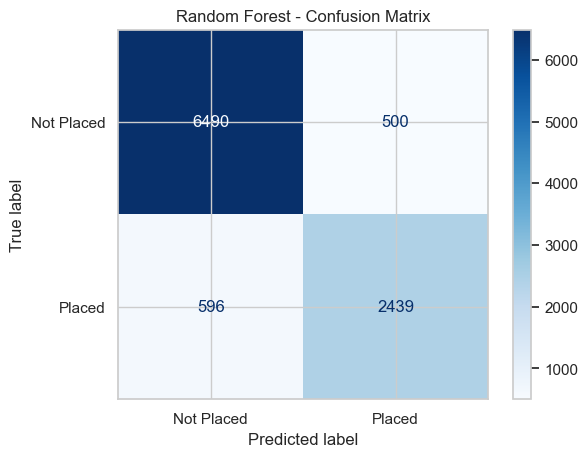

In [32]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Display confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Placed", "Placed"]
)

disp.plot(values_format="d", cmap="Blues")

plt.title("Random Forest - Confusion Matrix")
plt.show()

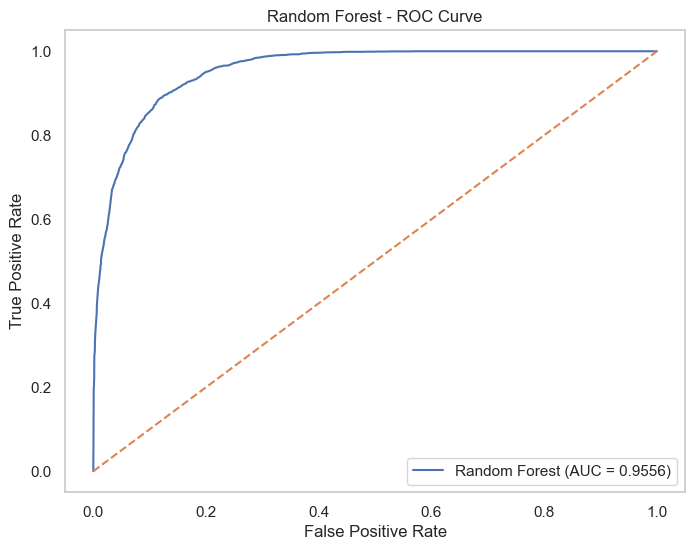

In [33]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Calculate ROC values
fpr, tpr, thresholds = roc_curve(y_test, y_probability)

roc_auc = roc_auc_score(y_test, y_probability)

# Plot ROC Curve
plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Random Forest (AUC = {roc_auc:.4f})"
)

plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Random Forest - ROC Curve")

plt.legend()
plt.grid()
plt.show()

In [34]:
# Extract feature importance

feature_importance = pd.DataFrame({
    "Feature": preprocessor.get_feature_names_out(),
    "Importance": rf_model.feature_importances_
})

# Sort features by importance
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

# Display top 20 features
display(feature_importance.head(20))

,Feature,Importance
4,numerical__technical_score,0.192438
9,numerical__years_of_experience,0.087735
14,numerical__interview_score_avg,0.071501
37,categorical__experience_level_junior,0.057128
16,numerical__placement_probability_score,0.056718
31,categorical__job_role_match_not matched,0.052232
17,numerical__ctc_gap,0.049775
7,numerical__skills_match_percentage,0.044298
26,categorical__internship_experience_yes,0.042647
11,numerical__expected_ctc_lpa,0.031106


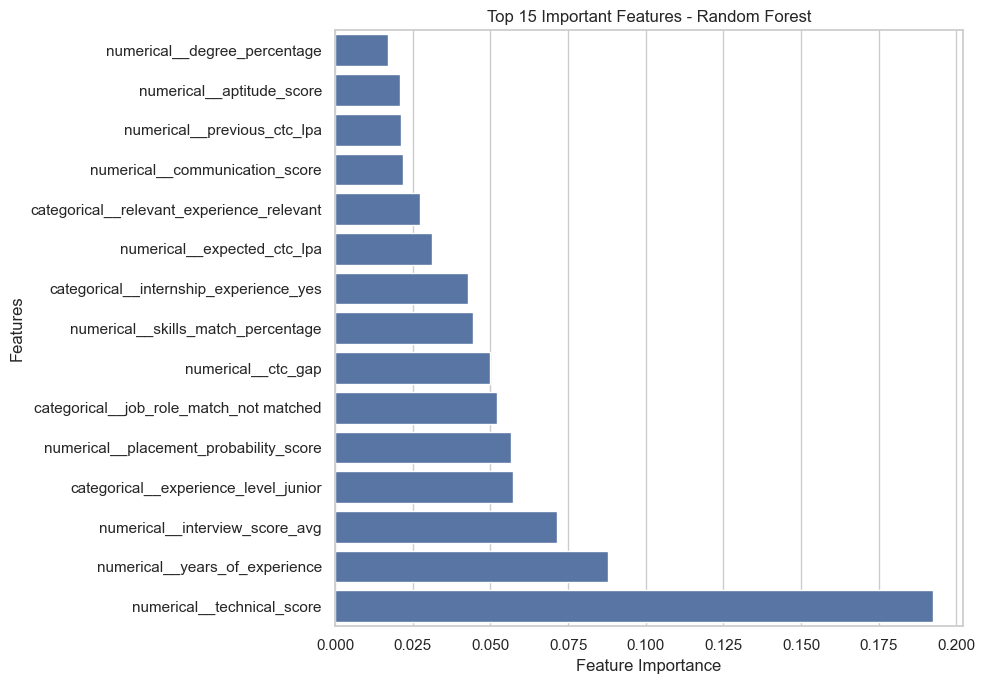

In [35]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select top 15 features
top_features = feature_importance.head(15).sort_values(
    by="Importance",
    ascending=True
)

# Plot feature importance
plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Important Features - Random Forest")
plt.xlabel("Feature Importance")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

In [36]:
import os
import joblib

# Create artifacts folder
ARTIFACTS_DIR = r"C:\Users\2SIN\Documents\Python\venv\Job_Acceptance\artifacts"

os.makedirs(ARTIFACTS_DIR, exist_ok=True)

# Save trained model
MODEL_PATH = os.path.join(
    ARTIFACTS_DIR,
    "job_acceptance_model.pkl"
)

joblib.dump(rf_model, MODEL_PATH)

print("Random Forest model saved successfully!")
print("Location:", MODEL_PATH)

Random Forest model saved successfully!
Location: C:\Users\2SIN\Documents\Python\venv\Job_Acceptance\artifacts\job_acceptance_model.pkl


In [37]:
# Save the fitted preprocessor

PREPROCESSOR_PATH = os.path.join(
    ARTIFACTS_DIR,
    "preprocessor.pkl"
)

joblib.dump(preprocessor, PREPROCESSOR_PATH)

print("Preprocessor saved successfully!")
print("Location:", PREPROCESSOR_PATH)

Preprocessor saved successfully!
Location: C:\Users\2SIN\Documents\Python\venv\Job_Acceptance\artifacts\preprocessor.pkl


In [38]:
import os

model_file = os.path.join(ARTIFACTS_DIR, "job_acceptance_model.pkl")
preprocessor_file = os.path.join(ARTIFACTS_DIR, "preprocessor.pkl")

print("MODEL FILE:", os.path.exists(model_file))
print("PREPROCESSOR FILE:", os.path.exists(preprocessor_file))

print("\nSaved Files:")
print(os.listdir(ARTIFACTS_DIR))

MODEL FILE: True
PREPROCESSOR FILE: True

Saved Files:
['feature_names.pkl', 'job_acceptance_model.pkl', 'preprocessor.pkl', 'X_test.pkl', 'X_train.pkl', 'X_train_balanced.pkl', 'y_test.pkl', 'y_train.pkl', 'y_train_balanced.pkl']


In [39]:
print("=" * 55)
print("JOB ACCEPTANCE PREDICTION SYSTEM")
print("RANDOM FOREST MODEL - FINAL SUMMARY")
print("=" * 55)

print("\nMODEL CONFIGURATION")
print("Algorithm       : Random Forest Classifier")
print("Number of Trees : 300")
print("Sampling        : SMOTE")
print("Train-Test Split: 80:20")

print("\nMODEL PERFORMANCE")
print(f"Accuracy        : {accuracy * 100:.2f}%")
print(f"Precision       : {precision:.4f}")
print(f"Recall          : {recall:.4f}")
print(f"F1 Score        : {f1:.4f}")
print(f"ROC-AUC         : {roc_auc:.4f}")

print("\nMODEL ARTIFACTS")
print("Model           : job_acceptance_model.pkl")
print("Preprocessor    : preprocessor.pkl")

print("\nSTATUS: MODEL TRAINING AND EVALUATION COMPLETED")
print("=" * 55)

JOB ACCEPTANCE PREDICTION SYSTEM
RANDOM FOREST MODEL - FINAL SUMMARY

MODEL CONFIGURATION
Algorithm       : Random Forest Classifier
Number of Trees : 300
Sampling        : SMOTE
Train-Test Split: 80:20

MODEL PERFORMANCE
Accuracy        : 89.07%
Precision       : 0.8299
Recall          : 0.8036
F1 Score        : 0.8165
ROC-AUC         : 0.9556

MODEL ARTIFACTS
Model           : job_acceptance_model.pkl
Preprocessor    : preprocessor.pkl

STATUS: MODEL TRAINING AND EVALUATION COMPLETED


In [40]:
import joblib

# Load saved model and preprocessor
loaded_model = joblib.load(MODEL_PATH)
loaded_preprocessor = joblib.load(PREPROCESSOR_PATH)

# Select one candidate from the test dataset
sample_candidate = X_test.iloc[[0]]

# Preprocess candidate details
sample_processed = loaded_preprocessor.transform(sample_candidate)

# Predict placement
prediction = loaded_model.predict(sample_processed)[0]

# Predict probability of placement
probability = loaded_model.predict_proba(sample_processed)[0, 1]

print("Predicted Status:", "Placed" if prediction == 1 else "Not Placed")
print(f"Placement Probability: {probability * 100:.2f}%")
print("Actual Status:", "Placed" if y_test.iloc[0] == 1 else "Not Placed")

Predicted Status: Not Placed
Placement Probability: 35.67%
Actual Status: Placed


In [41]:
# Select 10 candidates from test data
sample_candidates = X_test.iloc[:10]

# Preprocess candidates
sample_processed = loaded_preprocessor.transform(sample_candidates)

# Predict
predictions = loaded_model.predict(sample_processed)

# Get probabilities
probabilities = loaded_model.predict_proba(sample_processed)[:, 1]

# Compare predictions with actual results
results = pd.DataFrame({
    "Actual": y_test.iloc[:10].map({
        0: "Not Placed",
        1: "Placed"
    }).values,
    "Predicted": [
        "Placed" if p == 1 else "Not Placed"
        for p in predictions
    ],
    "Placement Probability (%)": (probabilities * 100).round(2)
})

results["Correct Prediction"] = (
    results["Actual"] == results["Predicted"]
)

display(results)

,Actual,Predicted,Placement Probability (%),Correct Prediction
0,Placed,Not Placed,35.67,False
1,Placed,Placed,65.67,True
2,Not Placed,Not Placed,0.33,True
3,Placed,Placed,97.67,True
4,Not Placed,Not Placed,10.67,True
5,Not Placed,Not Placed,38.67,True
6,Not Placed,Not Placed,7.33,True
7,Not Placed,Not Placed,4.00,True
8,Not Placed,Not Placed,5.67,True
9,Not Placed,Not Placed,1.67,True


In [42]:
feature_names = preprocessor.get_feature_names_out()

print("Feature names created successfully!")
print("Total processed features:", len(feature_names))

print(feature_names)

Feature names created successfully!
Total processed features: 43
['numerical__age_years' 'numerical__ssc_percentage'
 'numerical__hsc_percentage' 'numerical__degree_percentage'
 'numerical__technical_score' 'numerical__aptitude_score'
 'numerical__communication_score' 'numerical__skills_match_percentage'
 'numerical__certifications_count' 'numerical__years_of_experience'
 'numerical__previous_ctc_lpa' 'numerical__expected_ctc_lpa'
 'numerical__notice_period_days' 'numerical__employment_gap_months'
 'numerical__interview_score_avg' 'numerical__academic_avg'
 'numerical__placement_probability_score' 'numerical__ctc_gap'
 'numerical__has_certifications' 'numerical__long_notice_period'
 'numerical__employment_gap_flag' 'categorical__gender_male'
 'categorical__degree_specialization_electronics'
 'categorical__degree_specialization_information technology'
 'categorical__degree_specialization_mechanical'
 'categorical__degree_specialization_others'
 'categorical__internship_experience_yes'
 

In [43]:
import os
import joblib

ARTIFACTS_DIR = r"C:\Users\2SIN\Documents\Python\venv\Job_Acceptance\artifacts"

# Save feature names
joblib.dump(
    feature_names,
    os.path.join(ARTIFACTS_DIR, "feature_names.pkl")
)

# Save processed test data
joblib.dump(
    X_test_processed,
    os.path.join(ARTIFACTS_DIR, "X_test.pkl")
)

# Save actual test labels
joblib.dump(
    y_test,
    os.path.join(ARTIFACTS_DIR, "y_test.pkl")
)

print("All three artifacts saved successfully!")

All three artifacts saved successfully!


In [44]:
import os

required_files = [
    "job_acceptance_model.pkl",
    "preprocessor.pkl",
    "feature_names.pkl",
    "X_test.pkl",
    "y_test.pkl"
]

print("DASHBOARD ARTIFACT VERIFICATION")
print("-" * 40)

for file in required_files:
    path = os.path.join(ARTIFACTS_DIR, file)
    print(f"{file}: {'FOUND' if os.path.exists(path) else 'MISSING'}")

DASHBOARD ARTIFACT VERIFICATION
----------------------------------------
job_acceptance_model.pkl: FOUND
preprocessor.pkl: FOUND
feature_names.pkl: FOUND
X_test.pkl: FOUND
y_test.pkl: FOUND


In [45]:
print("Model feature columns:")
print(list(preprocessor.feature_names_in_))

print("\nCandidate test input columns:")
print(list(X_test.columns))

Model feature columns:
['age_years', 'gender', 'ssc_percentage', 'hsc_percentage', 'degree_percentage', 'degree_specialization', 'technical_score', 'aptitude_score', 'communication_score', 'skills_match_percentage', 'certifications_count', 'internship_experience', 'years_of_experience', 'career_switch_willingness', 'relevant_experience', 'previous_ctc_lpa', 'expected_ctc_lpa', 'company_tier', 'job_role_match', 'competition_level', 'bond_requirement', 'notice_period_days', 'layoff_history', 'employment_gap_months', 'relocation_willingness', 'interview_score_avg', 'experience_level', 'skills_level', 'academic_avg', 'academic_performance_band', 'interview_performance_category', 'placement_probability_score', 'ctc_gap', 'has_certifications', 'long_notice_period', 'employment_gap_flag']

Candidate test input columns:
['age_years', 'gender', 'ssc_percentage', 'hsc_percentage', 'degree_percentage', 'degree_specialization', 'technical_score', 'aptitude_score', 'communication_score', 'skills_ma

In [46]:
print("Candidate input values:")
print(X_test.iloc[0].to_string())

print("\nProcessed feature count:", X_test_processed.shape[1])
print("Model expected feature count:", rf_model.n_features_in_)

Candidate input values:
age_years                                       24
gender                                        male
ssc_percentage                           64.023741
hsc_percentage                           71.531198
degree_percentage                        66.301513
degree_specialization             computer science
technical_score                          86.934697
aptitude_score                           65.257235
communication_score                      61.366031
skills_match_percentage                  64.256636
certifications_count                             1
internship_experience                           no
years_of_experience                              1
career_switch_willingness              not willing
relevant_experience                       relevant
previous_ctc_lpa                           6.81507
expected_ctc_lpa                         10.226559
company_tier                                tier 2
job_role_match                             matched
competi

In [47]:
print("All columns in the original feature-engineered dataset:\n")

for col in df.columns:
    print(col)

All columns in the original feature-engineered dataset:

age_years
gender
ssc_percentage
hsc_percentage
degree_percentage
degree_specialization
technical_score
aptitude_score
communication_score
skills_match_percentage
certifications_count
internship_experience
years_of_experience
career_switch_willingness
relevant_experience
previous_ctc_lpa
expected_ctc_lpa
company_tier
job_role_match
competition_level
bond_requirement
notice_period_days
layoff_history
employment_gap_months
relocation_willingness
status
interview_score_avg
experience_level
skills_level
academic_avg
academic_performance_band
interview_performance_category
placement_probability_score
ctc_gap
has_certifications
long_notice_period
employment_gap_flag


In [48]:
engineered_columns = [
    "interview_score_avg",
    "experience_level",
    "skills_level",
    "academic_avg",
    "academic_performance_band",
    "interview_performance_category",
    "placement_probability_score",
    "ctc_gap",
    "has_certifications",
    "long_notice_period",
    "employment_gap_flag"
]

print(df[engineered_columns].head(10).to_string(index=False))

 interview_score_avg experience_level skills_level  academic_avg academic_performance_band interview_performance_category  placement_probability_score   ctc_gap  has_certifications  long_notice_period  employment_gap_flag
           70.754233          fresher         high     74.920254                    medium                        average                     0.755219  2.275293                   1                   0                    1
           62.532418          fresher         high     68.650839                    medium                        average                     0.686814  0.949584                   1                   0                    0
           70.175622          fresher         high     77.641017                      high                        average                     0.745318 -0.324979                   1                   0                    1
           64.539376          fresher         high     75.329142                      high                      

In [49]:
df["calculated_score"] = (
    0.40 * df["skills_match_percentage"]
    + 0.30 * df["interview_score_avg"]
    + 0.30 * df["academic_avg"]
) / 100

print(
    "Matching rows:",
    (df["calculated_score"].round(6) ==
     df["placement_probability_score"].round(6)).sum()
)

print("Total rows:", len(df))

Matching rows: 50124
Total rows: 50124


In [50]:
print("Experience levels:")
print(df["experience_level"].value_counts())

print("\nSkills levels:")
print(df["skills_level"].value_counts())

print("\nAcademic performance bands:")
print(df["academic_performance_band"].value_counts())

print("\nInterview performance categories:")
print(df["interview_performance_category"].value_counts())

Experience levels:
experience_level
fresher    28526
junior     21598
Name: count, dtype: int64

Skills levels:
skills_level
high      31659
medium    18465
Name: count, dtype: int64

Academic performance bands:
academic_performance_band
medium    37664
high      12339
low         121
Name: count, dtype: int64

Interview performance categories:
interview_performance_category
average      46257
excellent     3694
poor           173
Name: count, dtype: int64


In [51]:
print("Experience level verification:")

print(pd.crosstab(
    df["years_of_experience"],
    df["experience_level"]
).head(15))

print("\nSkills level verification:")

print(pd.crosstab(
    df["skills_match_percentage"],
    df["skills_level"]
).head(15))

Experience level verification:
experience_level     fresher  junior
years_of_experience                 
0                      14991       0
1                      13535       0
2                          0    9993
3                          0    6554
4                          0    3556
5                          0    1495

Skills level verification:
skills_level             high  medium
skills_match_percentage              
45.000000                   0     391
45.005967                   0       1
45.007180                   0       1
45.013380                   0       1
45.036646                   0       1
45.049675                   0       1
45.055713                   0       1
45.065718                   0       1
45.080992                   0       1
45.083867                   0       1
45.086468                   0       1
45.095580                   0       1
45.099064                   0       1
45.108527                   0       1
45.109997                   0       1

In [52]:
print("Model fitted with feature names:",
      hasattr(rf_model, "feature_names_in_"))

print("Training data type:",
      type(X_train_balanced))

print("Processed test data type:",
      type(X_test_processed))

print("Model feature count:",
      rf_model.n_features_in_)

Model fitted with feature names: False
Training data type: <class 'numpy.ndarray'>
Processed test data type: <class 'numpy.ndarray'>
Model feature count: 43


In [53]:
print("Categorical features:")
for i, col in enumerate(categorical_features):
    print(i, col)

Categorical features:
0 gender
1 degree_specialization
2 internship_experience
3 career_switch_willingness
4 relevant_experience
5 company_tier
6 job_role_match
7 competition_level
8 bond_requirement
9 layoff_history
10 relocation_willingness
11 experience_level
12 skills_level
13 academic_performance_band
14 interview_performance_category


In [54]:
print(df["skills_match_percentage"].describe())

print("\nSkills distribution:")
print(df["skills_level"].value_counts())

print("\nMinimum and maximum skills scores:")
print(df["skills_match_percentage"].min())
print(df["skills_match_percentage"].max())

count    50124.000000
mean        73.941400
std         11.801066
min         45.000000
25%         65.864353
50%         74.001772
75%         82.119869
max        100.000000
Name: skills_match_percentage, dtype: float64

Skills distribution:
skills_level
high      31659
medium    18465
Name: count, dtype: int64

Minimum and maximum skills scores:
45.0
100.0


In [55]:
print("Original dataset shape:", df.shape)

print("\nSkills scores below 45:")
print((df["skills_match_percentage"] < 45).sum())

print("\nSkills scores from 45 to 70:")
print(((df["skills_match_percentage"] >= 45) &
       (df["skills_match_percentage"] <= 70)).sum())

print("\nSkills scores above 70:")
print((df["skills_match_percentage"] > 70).sum())

Original dataset shape: (50124, 38)

Skills scores below 45:
0

Skills scores from 45 to 70:
18465

Skills scores above 70:
31659
